# Sampling the LJ13 Cluster with Parallel Tempering

The **LJ13** distribution is a Boltzmann distribution over 13 particles in 3D,
interacting through the Lennard-Jones 12-6 pair potential plus a harmonic trap:

$$
p(x) \propto \exp\bigl(-\beta\, U(x)\bigr), \qquad
U(x) = \underbrace{\sum_{i<j} \varepsilon \left[\left(\frac{r_m}{r_{ij}}\right)^{12}
- 2\left(\frac{r_m}{r_{ij}}\right)^6\right]}_{\text{LJ pair potential}}
+ \underbrace{\frac{s}{2} \sum_{i=1}^{13} \|x_i\|^2}_{\text{harmonic trap}}
$$

where $r_{ij} = \|x_i - x_j\|$ is the Euclidean distance between particles $i$ and $j$.
Each pair interaction has minimum $-\varepsilon$ at distance $r = r_m$.
The $r^{-12}$ term is short-range repulsion; the $-2r^{-6}$ term is long-range attraction.
The harmonic trap (strength $s$) centers the cluster at the origin and makes
the distribution proper (normalizable).

LJ13 has $\binom{13}{2} = 78$ interacting pairs. The global energy minimum
is the icosahedral configuration at $U \approx -44.33$ (without the trap contribution),
but the landscape contains hundreds of local minima separated by high barriers.
This makes LJ13 a standard benchmark for sampling methods.

The state vector $x \in \mathbb{R}^{39}$ stores $13 \times 3$ particle coordinates.

The LJ density is provided by the
[jax-pdf](https://github.com/alexxthiery/jax-pdf) package:

```bash
pip install -e git+https://github.com/alexxthiery/jax-pdf.git#egg=jax-pdf
```

In [1]:
%load_ext autoreload
%autoreload 2

from jax import config
config.update("jax_enable_x64", True)

In [2]:
import sys
from pathlib import Path

parent = Path().resolve().parent
if str(parent) not in sys.path:
    sys.path.insert(0, str(parent))

In [3]:
import jax
import jax.numpy as jnp
from jax import random
import numpy as np
import matplotlib.pyplot as plt

from jax_pdf import LennardJones
from mppt import PTProblem

In [21]:
n_atoms = 13
spatial_dim = 3
dim = n_atoms * spatial_dim  # 39

# LJ13 with harmonic trap (keeps the cluster centered, makes distribution proper)
length_scale = 1.
trap_scale = 1.0 / length_scale**2
lj = LennardJones(n_particles=n_atoms, trap_scale=trap_scale)

# Target: LJ13 log-density on R^39
def logpdf_final_target(x):
    return lj(x)

# Reference: standard normal in 39D
def rvs_ref(key):
    return random.normal(key, shape=(dim,))

def logpdf_ref(x):
    return -0.5 * jnp.sum(x**2) - 0.5 * dim * jnp.log(2 * jnp.pi)

problem = PTProblem(
    rvs_ref=rvs_ref,
    logpdf_ref=logpdf_ref,
    logpdf_final_target=logpdf_final_target,
)

# Quick check: evaluate at a random point
x_test = random.normal(random.key(0), shape=(dim,))
print(f"logpdf_ref(x_test) = {logpdf_ref(x_test):.4f}")
print(f"logpdf_target(x_test) = {logpdf_final_target(x_test):.4f}")

logpdf_ref(x_test) = -57.2830
logpdf_target(x_test) = -159237.6268


## Sampling strategy

Same two-phase approach as DW4:

1. **SMC sampler** to anneal from the reference to the target, discovering
   a temperature schedule adaptively.

2. **Parallel tempering** using the SMC temperatures, initialized from the
   SMC output particles.

LJ13 in 39D is significantly harder than DW4 in 6D, so SMC will discover
more intermediate temperatures and each HMC step is more expensive.

See [docs/api.md](../docs/api.md) for the full API reference: available MCMC
engines, explorer modes, swapper options, and collectors.

In [22]:
from mppt.ui.ui_main import smc_sampler

key = random.key(42)
n_particles = 10_000

smc_output, logZ_smc, temperatures = smc_sampler(
    key, problem,
    n_particles=n_particles,
    engine={'name': 'random_walk'},
    n_mcmc_steps=50,
    local_ess_ratio=0.5,
    verbose=True,
    runtime_check=False,
    keep_all_states=True,
)

temperatures = np.array(temperatures)
print(f"\n{len(temperatures)} temperatures: " + " < ".join(f"{t:.3f}" for t in temperatures))

Initializing and compiling...


iter  1 | t=1.07e-04 | acc=0.14 | niter=50 | logZ=(-0.826, -0.828, -0.827)
iter  2 | t=0.003280 | acc=0.09 | niter=50 | logZ=(-0.813, -0.812, -0.817)
iter  3 | t=0.034428 | acc=0.06 | niter=50 | logZ=(0.376, 0.378, 0.384)
iter  4 | t=0.200386 | acc=0.03 | niter=50 | logZ=(6.473, 6.473, 6.476)
iter  5 | t=0.437771 | acc=0.01 | niter=50 | logZ=(10.339, 10.335, 10.334)
iter  6 | t=0.679354 | acc=0.01 | niter=50 | logZ=(11.209, 11.208, 11.208)
iter  7 | t=1.000000 | acc=0.00 | niter=50 | logZ=(15.904, 15.901, 15.901)
logZ total=(42.662, 42.654, 42.659)  [SMC_like, reverse_logistic, robust]

8 temperatures: 0.000 < 0.000 < 0.003 < 0.034 < 0.200 < 0.438 < 0.679 < 1.000


In [23]:
from mppt.ui.ui_main import pt_manual_runners
from tqdm import trange

pt_runner = pt_manual_runners(
    problem, temperatures,
    n_particles=n_particles,
    engine={'name': 'hmc', 'refresh_rate': 0.07},
    explorer={'mode': 'adaptive', 'niter': 10},
    swapper={'mix': True},
)



Compiling PT runner:


  initializer (1.8s)
  SMC initializer (1.4s)
  one-step (compact) (23.5s)
  one-step (full) (22.9s)
Compilation done.


In [31]:
key = random.key(1)
pt_state = smc_output

n_pt_iters = 100
diagnostics = []
for i in trange(n_pt_iters):
    key, subkey = random.split(key)
    full = (i == n_pt_iters - 1)
    pt_state, diag = pt_runner(subkey, pt_state, full_output=full)
    diagnostics.append(diag)

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:45<00:00,  2.18it/s]


## Diagnostics

Key quantities to monitor:

- **Swap rejection rates** (one per adjacent temperature pair): high rejection
  rates indicate the temperature gap is too large for efficient mixing.
- **MCMC acceptance rates** (one per temperature): HMC targets 0.8--0.95.
  Temperature 0 is always 1.0 (iid sampling from the reference).
- **logZ estimates**: three estimators (SMC-like, robust, reverse logistic)
  should roughly agree if the chain has converged.


logZ estimates at last iteration:
  logZ_SMC_like: 42.0034
  logZ_reverse_logistic: 42.0176
  logZ_robust: 42.0160


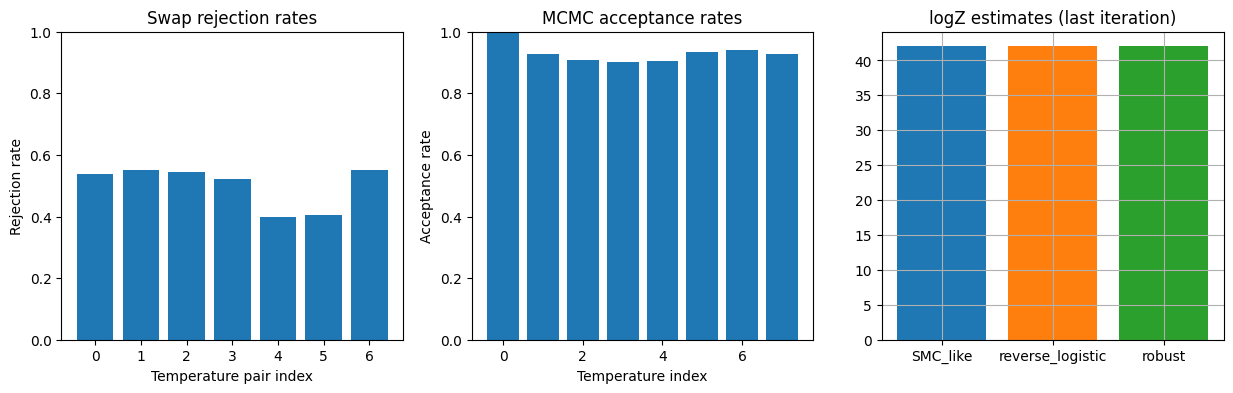

In [32]:
last_diag = diagnostics[-1]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Swap rejection rates
axes[0].bar(range(len(temperatures) - 1), last_diag['swap_rejection_rates'])
axes[0].set_xlabel('Temperature pair index')
axes[0].set_ylabel('Rejection rate')
axes[0].set_title('Swap rejection rates')
axes[0].set_ylim(0, 1)

# MCMC acceptance rates
axes[1].bar(range(len(temperatures)), last_diag['mcmc_acc_rates'])
axes[1].set_xlabel('Temperature index')
axes[1].set_ylabel('Acceptance rate')
axes[1].set_title('MCMC acceptance rates')
axes[1].set_ylim(0, 1)

# logZ estimates as bar plot
for name in ['logZ_SMC_like', 'logZ_reverse_logistic', 'logZ_robust']:
    if name in last_diag:
        axes[2].bar(name.replace('logZ_', ''), last_diag[name])
axes[2].set_title('logZ estimates (last iteration)')
axes[2].grid(True)

print("\nlogZ estimates at last iteration:")
for name in ['logZ_SMC_like', 'logZ_reverse_logistic', 'logZ_robust']:
    if name in last_diag:
        print(f"  {name}: {last_diag[name]:.4f}")

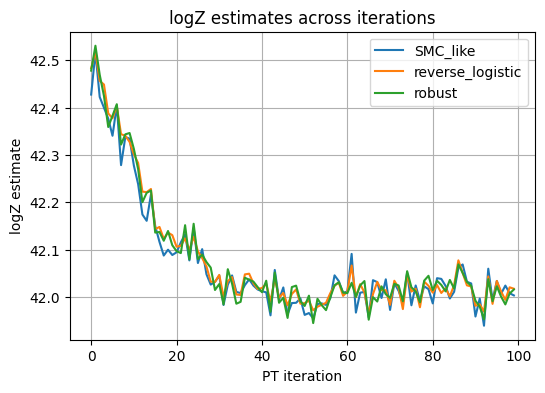

In [33]:
# plot logZ estimates across iterations
fig2, ax2 = plt.subplots(figsize=(6, 4))
for name in ['logZ_SMC_like', 'logZ_reverse_logistic', 'logZ_robust']:
    if name in diagnostics[0]:
        ax2.plot([diag[name] for diag in diagnostics], label=name.replace('logZ_', ''))
ax2.set_title('logZ estimates across iterations')
ax2.set_xlabel('PT iteration')
ax2.set_ylabel('logZ estimate')
ax2.legend()
ax2.grid(True)


## Visualizing samples

Extract particles at the target temperature ($t=1$) and reshape
the 39D vectors into 13 particles in 3D.

In [34]:
# Extract particles at the final temperature (t=1)
samples = pt_state.X.position[pt_state.Z[-1]]  # shape (n_particles, 39)
particles = samples.reshape(-1, n_atoms, spatial_dim)  # (n_particles, 13, 3)

print(f"Sample shape: {particles.shape} -- (n_particles, 13 atoms, 3D)")

Sample shape: (10000, 13, 3) -- (n_particles, 13 atoms, 3D)


/tmp/ipykernel_1271808/2178321943.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()


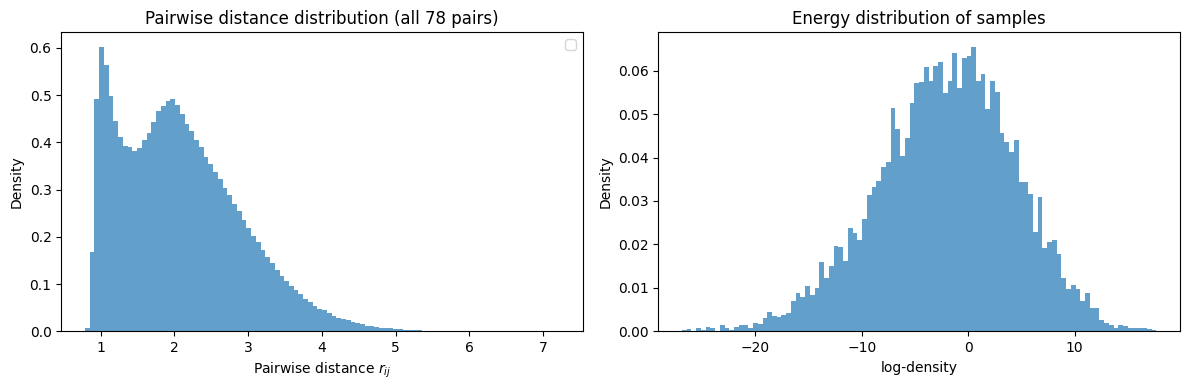

In [35]:
# Compute all pairwise distances for each sample
i_idx, j_idx = np.triu_indices(n_atoms, k=1)  # 78 unique pairs
diffs = particles[:, i_idx] - particles[:, j_idx]  # (n_particles, 78, 3)
distances = np.sqrt(np.sum(diffs**2, axis=-1))     # (n_particles, 78)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pairwise distance histogram (all 78 pairs pooled)
axes[0].hist(np.array(distances).ravel(), bins=100, density=True, alpha=0.7)
axes[0].set_xlabel('Pairwise distance $r_{ij}$')
axes[0].set_ylabel('Density')
axes[0].set_title('Pairwise distance distribution (all 78 pairs)')
axes[0].legend()

# Energy histogram
energies = jax.vmap(lj)(np.array(samples))
axes[1].hist(np.array(energies), bins=100, density=True, alpha=0.7)
axes[1].set_xlabel('log-density')
axes[1].set_ylabel('Density')
axes[1].set_title('Energy distribution of samples')

fig.tight_layout()
plt.show()

## Structural analysis

### Cluster radius

The root-mean-square distance from the center of mass measures how
spread out each cluster configuration is:

$$
R_{\text{cluster}} = \sqrt{\frac{1}{N_{\text{atoms}}} \sum_{i=1}^{N_{\text{atoms}}} \|x_i - \bar{x}\|^2}
$$

For the icosahedral LJ13 minimum, this is approximately 1.05.

### Radial distribution function

The radial distribution function $g(r)$ is the histogram of pairwise distances
normalized by the volume of a spherical shell $4\pi r^2 \, dr$.
Peaks in $g(r)$ reveal the shell structure of the cluster: the first peak
corresponds to nearest neighbors, the second to next-nearest neighbors, etc.

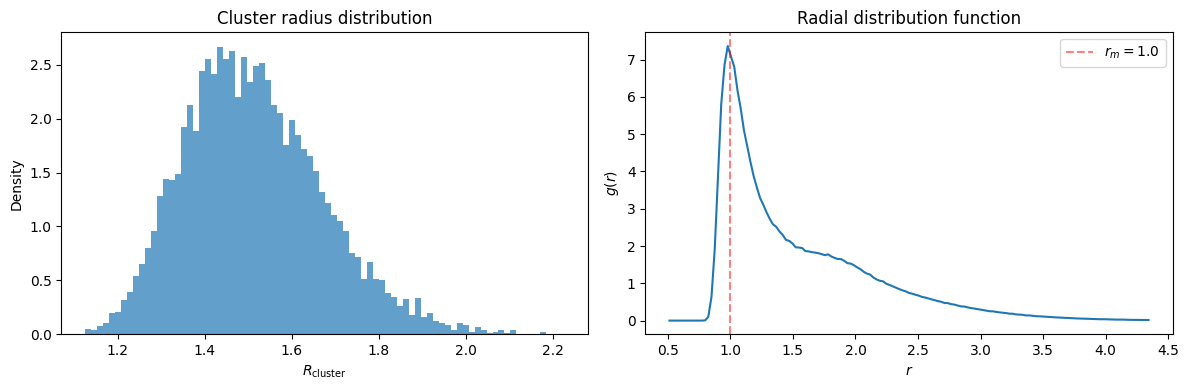

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Cluster radius: RMS distance from center of mass
com = particles.mean(axis=1, keepdims=True)  # (n_particles, 1, 3)
displacements = particles - com               # (n_particles, 13, 3)
r_cluster = np.sqrt(np.mean(np.sum(displacements**2, axis=-1), axis=-1))  # (n_particles,)

axes[0].hist(np.array(r_cluster), bins=80, density=True, alpha=0.7)
axes[0].set_xlabel('$R_{\\mathrm{cluster}}$')
axes[0].set_ylabel('Density')
axes[0].set_title('Cluster radius distribution')

# Radial distribution function g(r)
# Normalize the pairwise distance histogram by the shell volume 4*pi*r^2*dr
r_flat = np.array(distances).ravel()
r_max = float(np.percentile(r_flat, 99))
bins = np.linspace(0.5, r_max, 150)
counts, edges = np.histogram(r_flat, bins=bins, density=False)
r_centers = 0.5 * (edges[:-1] + edges[1:])
dr = edges[1] - edges[0]
shell_volume = 4 * np.pi * r_centers**2 * dr
# Normalize: divide by shell volume and number of samples
n_samples = len(distances)
n_pairs = distances.shape[1]  # 78
g_r = counts / (shell_volume * n_samples * n_pairs / len(bins))

axes[1].plot(r_centers, g_r)
axes[1].set_xlabel('$r$')
axes[1].set_ylabel('$g(r)$')
axes[1].set_title('Radial distribution function')
axes[1].axvline(1.0, color='red', linestyle='--', alpha=0.5, label='$r_m = 1.0$')
axes[1].legend()

fig.tight_layout()
plt.show()